In [1]:
import kagglehub
kaggle_path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.


In [ ]:
from pathlib import Path
import random

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

from sklearn.metrics import confusion_matrix, classification_report

SEED = 111

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

DATA_ROOT = Path("/kaggle/input/brain-tumor-mri-dataset")

IMAGE_SIZE = (168, 168)
BATCH_SIZE = 32
EPOCHS = 50
NUM_WORKERS = 0

CHECKPOINT_PATH = Path("best_brain_tumor_cnn.pt")

PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [ ]:
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize(IMAGE_SIZE),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ColorJitter(contrast=0.1),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.0015, 0.0015),
        scale=(0.99, 1.05)
    ),

    transforms.ToTensor(),
])


eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
])

In [4]:
train_dir = DATA_ROOT / "Training"
test_dir = DATA_ROOT / "Testing"

train_dataset = datasets.ImageFolder(
    root=train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    root=test_dir,
    transform=eval_transform
)

class_to_idx = train_dataset.class_to_idx
idx_to_class = {index: name for name, index in class_to_idx.items()}
class_names = list(class_to_idx.keys())

num_classes = len(class_names)

print(f"Classes: {class_names}")
print(f"Number of classes: {num_classes}")

print(f"\nTraining images: {len(train_dataset)}")
print(f"Testing images:  {len(test_dataset)}")

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4

Training images: 5600
Testing images:  1600


In [14]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)


print(f"Train batches: {len(train_loader)}")
print(f"Test batches:  {len(test_loader)}")

Train batches: 175
Test batches:  50


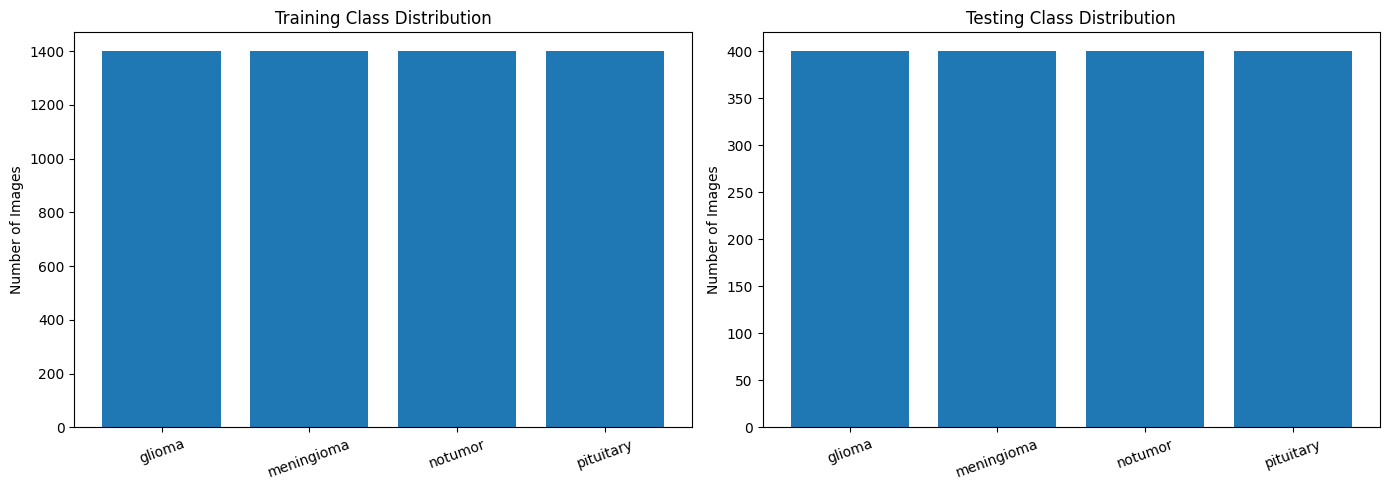

In [6]:
def get_class_counts(dataset):
    targets = np.array(dataset.targets)

    return [
        int(np.sum(targets == class_id))
        for class_id in range(len(class_names))
    ]


train_counts = get_class_counts(train_dataset)
test_counts = get_class_counts(test_dataset)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(class_names, train_counts)
axes[0].set_title("Training Class Distribution")
axes[0].set_ylabel("Number of Images")
axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(class_names, test_counts)
axes[1].set_title("Testing Class Distribution")
axes[1].set_ylabel("Number of Images")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

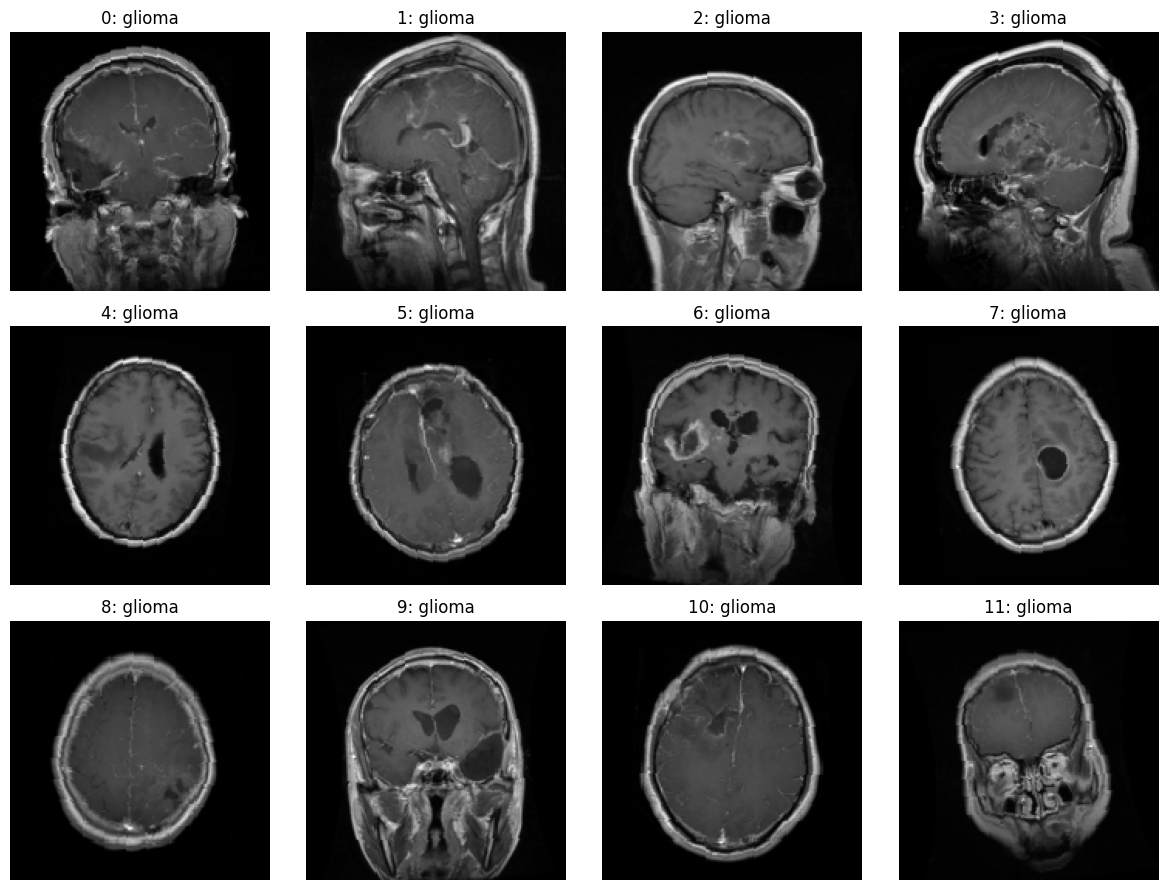

In [7]:
def show_samples(dataset, n=12):
    n = min(n, len(dataset))

    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
    axes = axes.flatten()

    for i in range(n):
        image, label = dataset[i]

        axes[i].imshow(image.squeeze(), cmap="gray")
        axes[i].set_title(
            f"{i}: {idx_to_class[label]}"
        )
        axes[i].axis("off")

    for i in range(n, len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


show_samples(train_dataset, n=12)

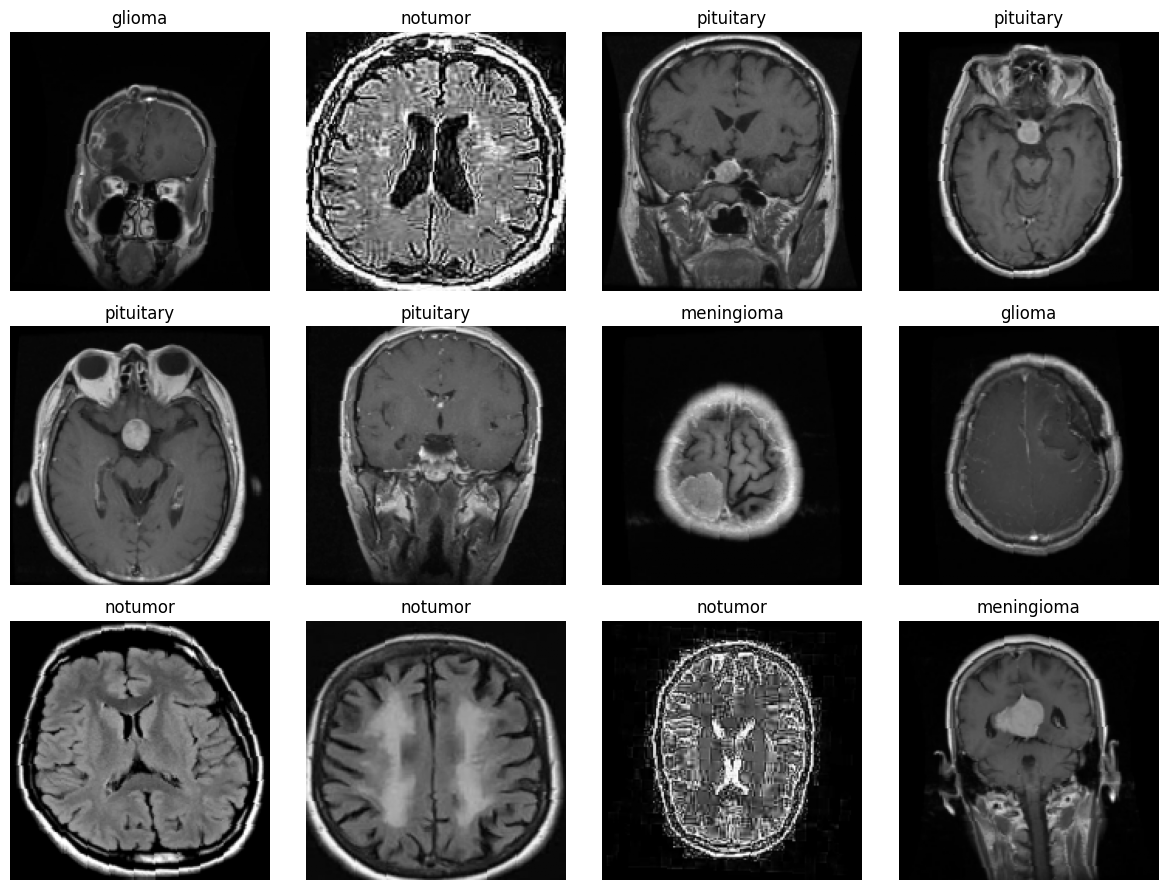

In [8]:
def show_augmented_samples(dataset, n=12):
    images, labels = next(iter(
        DataLoader(dataset, batch_size=n, shuffle=True)
    ))

    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
    axes = axes.flatten()

    for i in range(n):
        axes[i].imshow(images[i].squeeze(), cmap="gray")
        axes[i].set_title(idx_to_class[labels[i].item()])
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


show_augmented_samples(train_dataset)

In [ ]:
class BrainTumorCNN(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        self.feature_extractor = nn.Sequential(

            nn.Conv2d(1, 64, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3),

            nn.Conv2d(64, 64, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3),

            nn.Conv2d(64, 128, kernel_size=4),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(128, 128, kernel_size=4),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 512),
            nn.ReLU(),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.feature_extractor(x)
        return self.classifier(x)


model = BrainTumorCNN(num_classes).to(device)

print(model)

total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print(f"\nTrainable parameters: {total_params:,}")

BrainTumorCNN(
  (feature_extractor): Sequential(
    (0): Conv2d(1, 64, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=3, stride=3, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=3, stride=3, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(4, 4), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 128, kernel_size=(4, 4), stride=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=4, bias=True)
  )
)

Trainable parameters: 565,700


In [10]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    betas=(0.85, 0.9925)
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.8,
    patience=4,
    min_lr=1e-4
)

In [11]:
from tqdm.auto import tqdm


def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None

    model.train() if is_training else model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        loader,
        desc="Training" if is_training else "Validation",
        leave=False
    )

    for images, labels in progress:
        images = images.to(device)
        labels = labels.to(device)

        if is_training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_training:
                loss.backward()
                optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [15]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_accuracy = -1.0


for epoch in range(EPOCHS):

    print(f"\nEpoch [{epoch + 1}/{EPOCHS}]")

    train_loss, train_acc = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = run_epoch(
        model,
        test_loader,
        criterion
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    if val_acc > best_accuracy:
        best_accuracy = val_acc

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_to_idx": class_to_idx,
                "image_size": IMAGE_SIZE,
                "best_val_accuracy": best_accuracy
            },
            CHECKPOINT_PATH
        )

        print("Best model saved.")


Epoch [1/50]


Training:   0%|          | 0/175 [00:00<?, ?it/s]

Validation:   0%|          | 0/50 [00:00<?, ?it/s]

Train Loss: 0.0703 | Train Acc: 0.9741 | Val Loss: 0.8015 | Val Acc: 0.9150 | LR: 0.001000
Best model saved.

Epoch [2/50]


Training:   0%|          | 0/175 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/50 [00:00<?, ?it/s]

Train Loss: 0.0019 | Train Acc: 0.9993 | Val Loss: 1.7933 | Val Acc: 0.9425 | LR: 0.000134

Epoch [50/50]


Training:   0%|          | 0/175 [00:00<?, ?it/s]

Validation:   0%|          | 0/50 [00:00<?, ?it/s]

Train Loss: 0.0030 | Train Acc: 0.9988 | Val Loss: 1.8679 | Val Acc: 0.9387 | LR: 0.000107


In [17]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()


test_loss, test_accuracy = run_epoch(
    model,
    test_loader,
    criterion
)

print(f"Best validation accuracy: {checkpoint['best_val_accuracy']:.4f}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

Validation:   0%|          | 0/50 [00:00<?, ?it/s]

Best validation accuracy: 0.9450
Test loss: 0.9525
Test accuracy: 94.50%


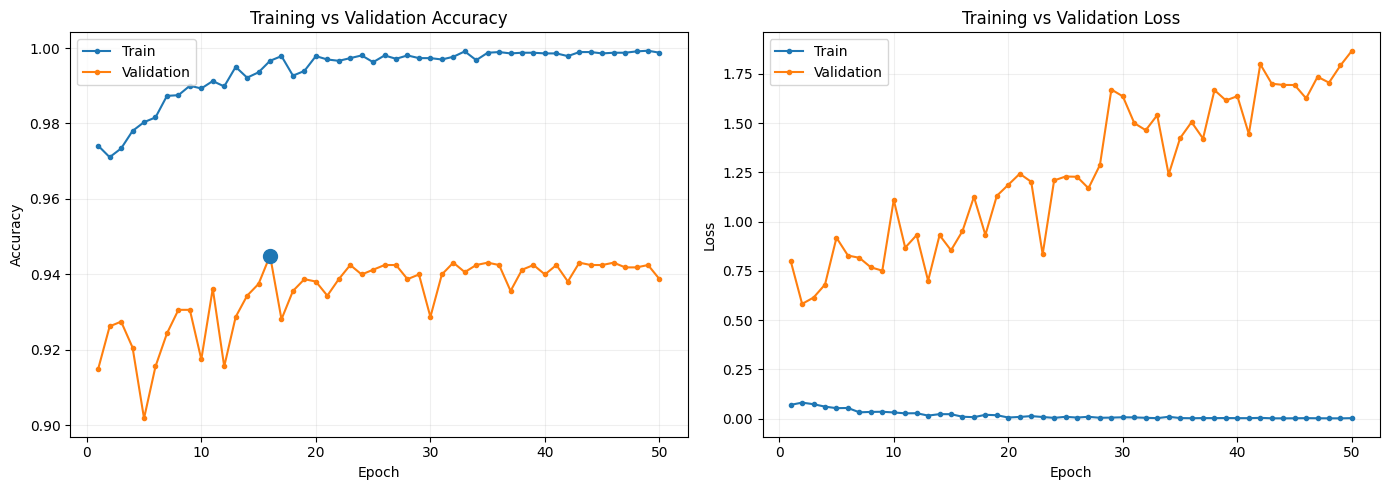

Best validation accuracy occurred at epoch 16.


In [ ]:
epochs_range = range(1, EPOCHS + 1)

best_epoch = np.argmax(history["val_accuracy"]) + 1


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    epochs_range,
    history["train_accuracy"],
    marker="o",
    markersize=3,
    label="Train"
)

axes[0].plot(
    epochs_range,
    history["val_accuracy"],
    marker="o",
    markersize=3,
    label="Validation"
)

axes[0].scatter(
    best_epoch,
    history["val_accuracy"][best_epoch - 1],
    s=100,
    zorder=5
)

axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(
    epochs_range,
    history["train_loss"],
    marker="o",
    markersize=3,
    label="Train"
)

axes[1].plot(
    epochs_range,
    history["val_loss"],
    marker="o",
    markersize=3,
    label="Validation"
)

axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Best validation accuracy occurred at epoch {best_epoch}.")

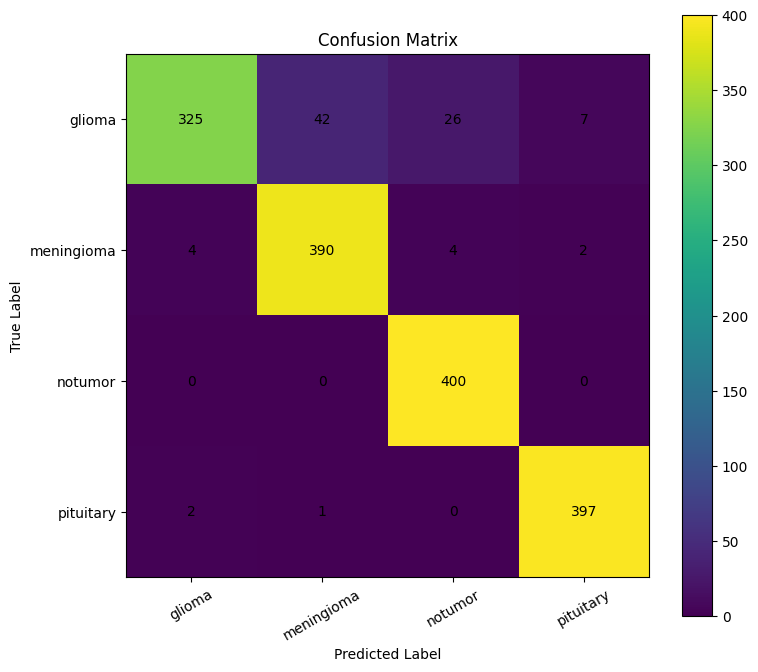

              precision    recall  f1-score   support

      glioma     0.9819    0.8125    0.8892       400
  meningioma     0.9007    0.9750    0.9364       400
     notumor     0.9302    1.0000    0.9639       400
   pituitary     0.9778    0.9925    0.9851       400

    accuracy                         0.9450      1600
   macro avg     0.9477    0.9450    0.9436      1600
weighted avg     0.9477    0.9450    0.9436      1600



In [19]:
def collect_predictions(model, loader):
    true_labels = []
    predicted_labels = []

    model.eval()

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            true_labels.extend(labels.cpu().numpy())
            predicted_labels.extend(predictions.cpu().numpy())

    return np.array(true_labels), np.array(predicted_labels)


true_labels, predicted_labels = collect_predictions(
    model,
    test_loader
)


cm = confusion_matrix(
    true_labels,
    predicted_labels
)


plt.figure(figsize=(8, 7))
plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    range(num_classes),
    class_names,
    rotation=30
)

plt.yticks(
    range(num_classes),
    class_names
)

for row in range(num_classes):
    for col in range(num_classes):
        plt.text(
            col,
            row,
            cm[row, col],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()


print(
    classification_report(
        true_labels,
        predicted_labels,
        target_names=class_names,
        digits=4
    )
)

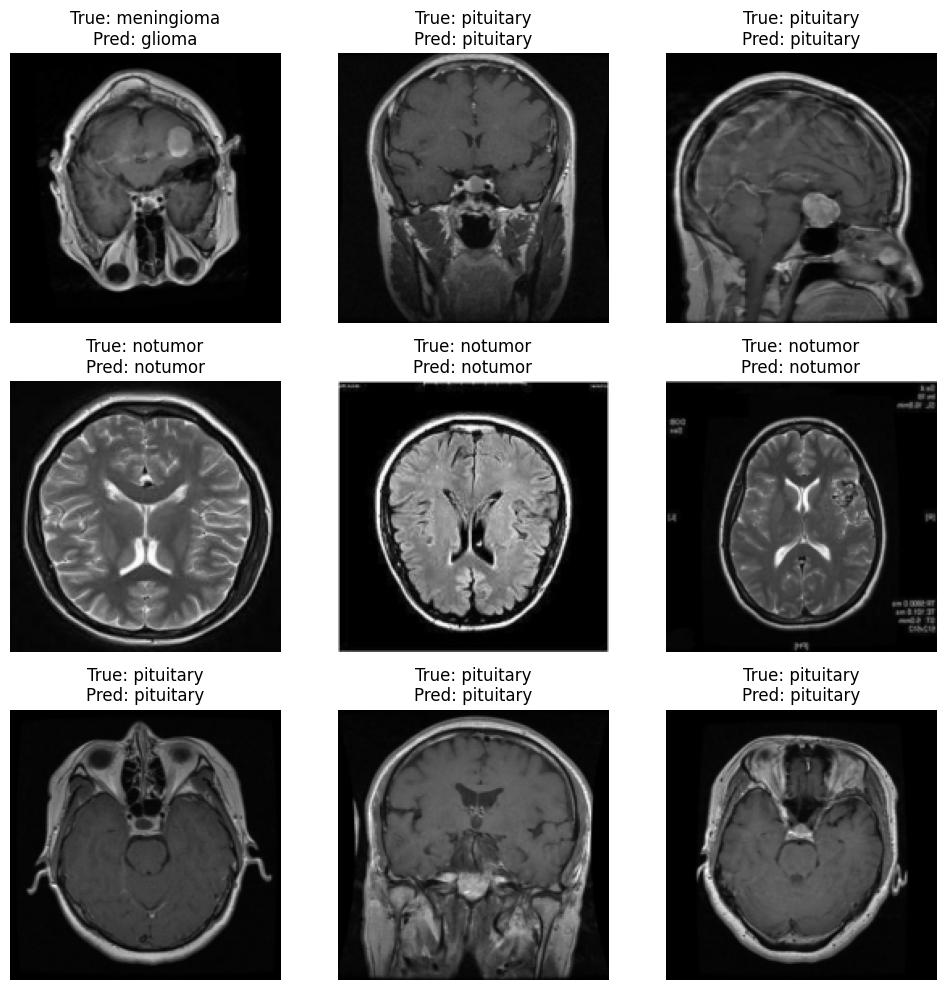

In [20]:
def show_predictions(model, dataset, n=9):
    loader = DataLoader(dataset, batch_size=n, shuffle=True)

    images, labels = next(iter(loader))
    images_for_model = images.to(device)

    model.eval()

    with torch.no_grad():
        outputs = model(images_for_model)
        predictions = outputs.argmax(dim=1).cpu()

    fig, axes = plt.subplots(3, 3, figsize=(10, 10))
    axes = axes.flatten()

    for i in range(n):
        true_class = idx_to_class[labels[i].item()]
        predicted_class = idx_to_class[predictions[i].item()]

        axes[i].imshow(
            images[i].squeeze(),
            cmap="gray"
        )

        axes[i].set_title(
            f"True: {true_class}\nPred: {predicted_class}"
        )

        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


show_predictions(model, test_dataset, n=9)

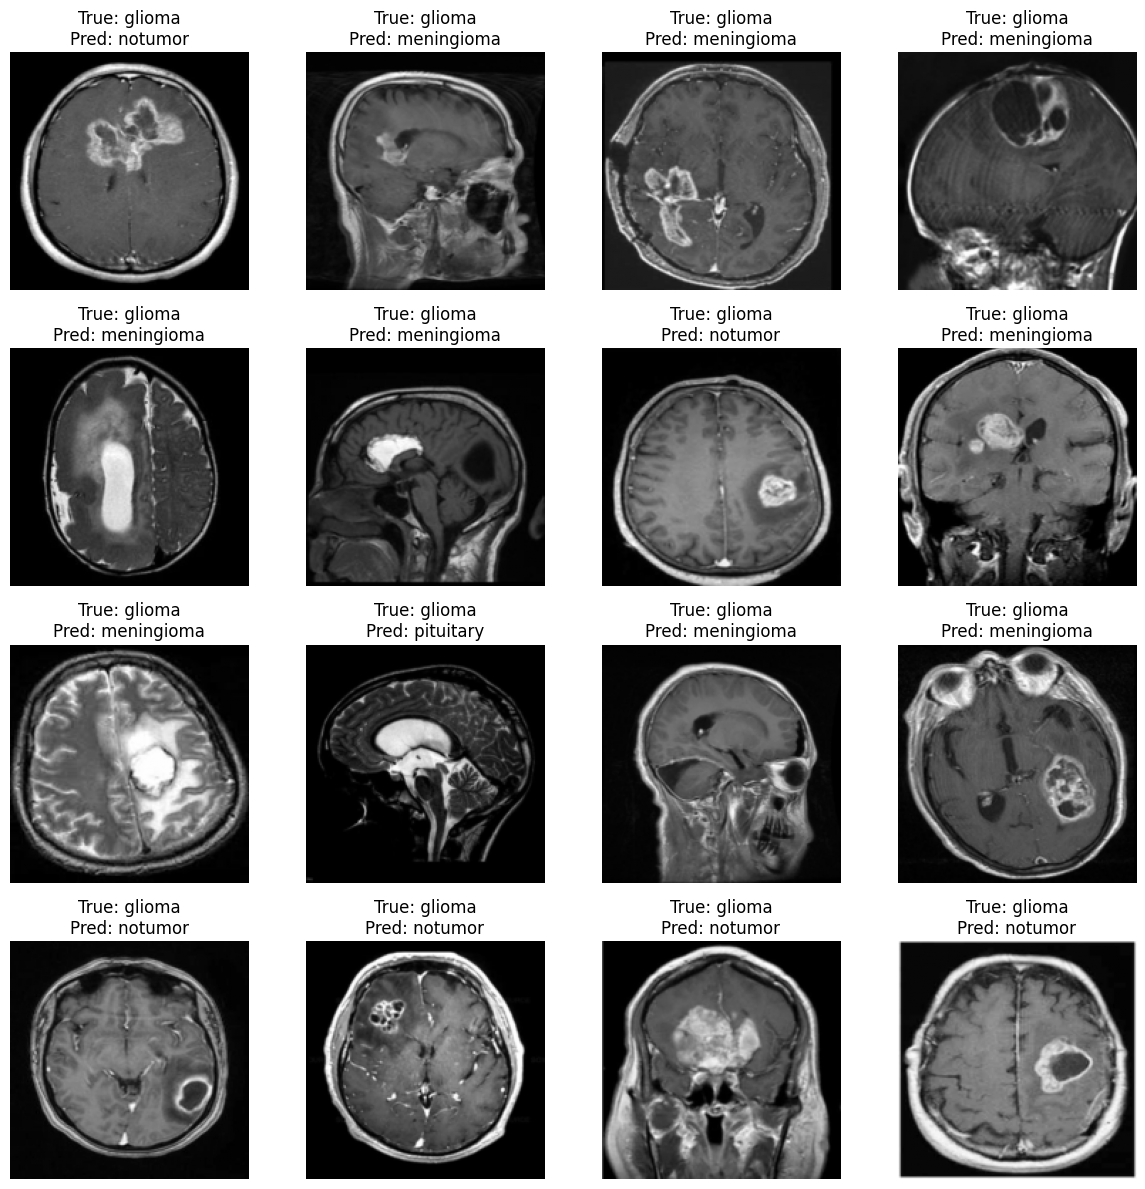

In [21]:
def show_misclassified(model, dataset, max_images=16):
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)

    wrong_images = []
    wrong_true = []
    wrong_pred = []

    model.eval()

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1).cpu()

            incorrect = predictions != labels

            for image, true_label, predicted_label in zip(
                images.cpu()[incorrect],
                labels[incorrect],
                predictions[incorrect]
            ):
                wrong_images.append(image)
                wrong_true.append(true_label.item())
                wrong_pred.append(predicted_label.item())

                if len(wrong_images) >= max_images:
                    break

            if len(wrong_images) >= max_images:
                break

    if not wrong_images:
        print("No misclassified images found.")
        return

    cols = 4
    rows = int(np.ceil(len(wrong_images) / cols))

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(12, rows * 3)
    )

    axes = np.array(axes).reshape(-1)

    for i, (image, true_label, predicted_label) in enumerate(
        zip(wrong_images, wrong_true, wrong_pred)
    ):
        axes[i].imshow(
            image.squeeze(),
            cmap="gray"
        )

        axes[i].set_title(
            f"True: {idx_to_class[true_label]}\n"
            f"Pred: {idx_to_class[predicted_label]}"
        )

        axes[i].axis("off")

    for i in range(len(wrong_images), len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


show_misclassified(
    model,
    test_dataset,
    max_images=16
)

In [29]:
def predict_image(model, image_path):
    image = Image.open(image_path)

    tensor = eval_transform(image)
    tensor = tensor.unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():
        logits = model(tensor)
        probabilities = torch.softmax(logits, dim=1)

    predicted_index = probabilities.argmax(dim=1).item()
    predicted_class = idx_to_class[predicted_index]

    return predicted_class, probabilities.squeeze().cpu().numpy()


def display_predictions(image_paths, true_labels):
    fig, axes = plt.subplots(
        1,
        len(image_paths),
        figsize=(18, 5)
    )

    if len(image_paths) == 1:
        axes = [axes]

    for ax, path, true_label in zip(
        axes,
        image_paths,
        true_labels
    ):

        predicted_class, probabilities = predict_image(
            model,
            path
        )

        image = Image.open(path).convert("L")
        image = image.resize(IMAGE_SIZE)

        ax.imshow(image, cmap="gray")
        ax.set_title(
            f"True: {true_label}\n"
            f"Pred: {predicted_class}"
        )
        ax.axis("off")

        print(f"\nImage: {Path(path).name}")
        print(f"True class: {true_label}")
        print(f"Predicted: {predicted_class}")
        print(
            "Probabilities:",
            np.round(probabilities, 3)
        )

    plt.tight_layout()
    plt.show()

In [ ]:
normal_image_path = (
    "/kaggle/input/brain-tumors-dataset/"
    "Data/Normal/N_100.jpg"
)

glioma_image_path = (
    "/kaggle/input/brain-tumors-dataset/"
    "Data/Tumor/glioma_tumor/G_10.jpg"
)

meningioma_image_path = (
    "/kaggle/input/brain-tumors-dataset/"
    "Data/Tumor/meningioma_tumor/M_101_HF_.jpg"
)

pituitary_image_path = (
    "/kaggle/input/brain-tumors-dataset/"
    "Data/Tumor/pituitary_tumor/P_100_HF_.jpg"
)


image_paths = [
    normal_image_path,
    glioma_image_path,
    meningioma_image_path,
    pituitary_image_path
]

true_labels = [
    "Notumor",
    "Glioma",
    "Meninigioma",
    "Pituitary"
]


display_predictions(
    image_paths,
    true_labels
)